Total genome length from header: 4,633,651 bp
Total reads processed: 576
  - unmapped      : 430 reads filtered out
  - low_mapq      : 0 reads filtered out
  - secondary     : 0 reads filtered out
  - supplementary : 74 reads filtered out
  - Kept for analysis: 72 reads

Step 4: Aggregating data...
  - Data aggregation complete.

Step 5: Creating genome-wide plot...
  - Found 5 sites with counts >= 0 to label.


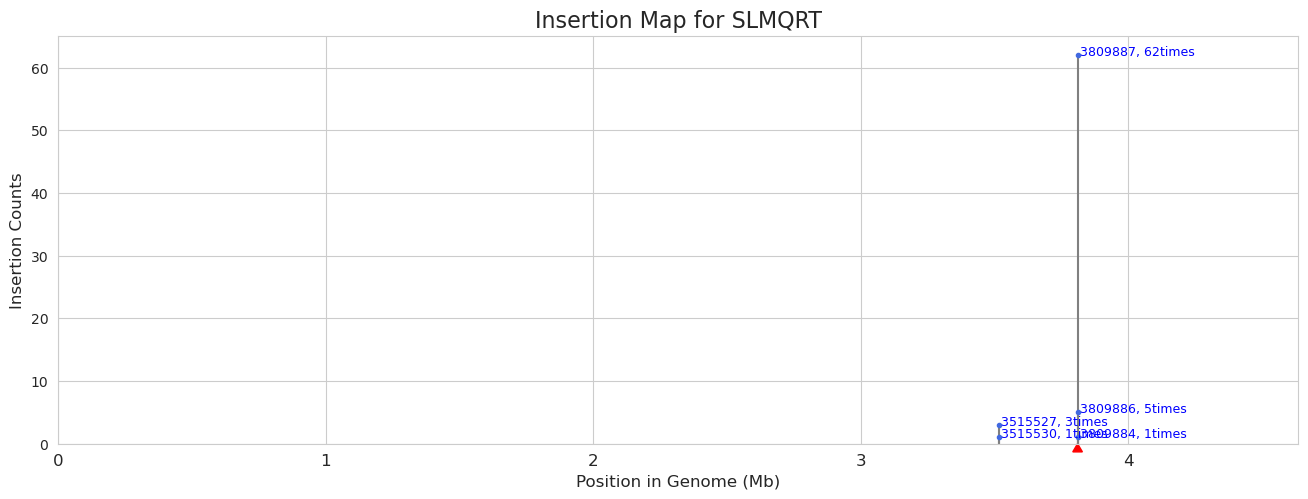

In [31]:
import pysam
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import argparse
from collections import Counter


alignment_file="../data/SLMQRT_half_kan/aligned_contigs.bam"
title="Insertion Map for SLMQRT"


# Set a professional style for the plots.
sns.set_style("whitegrid")

# Counter for tracking filtered reads.
filter_counts = Counter({
    "unmapped": 0,
    "low_mapq": 0,
    "secondary": 0,
    "supplementary": 0,
})
insertion_sites = []
total_genome_length = 0

# Open the SAM/BAM file once to process reads and get header info.
with pysam.AlignmentFile(alignment_file, "r") as samfile:
    # Get total genome length from the SAM/BAM header.
    if samfile.header.lengths:
        total_genome_length = sum(samfile.header.lengths)
        print(f"Total genome length from header: {total_genome_length:,} bp")

    # Process all aligned reads in the file.
    for read in samfile.fetch(until_eof=True):
        # Check which filtering condition the read meets.
        if read.is_unmapped:
            filter_counts["unmapped"] += 1
            continue
        # MAPQ=0 often means a read maps to multiple locations.
        if read.mapping_quality == 0:
            filter_counts["low_mapq"] += 1
            continue
        # Secondary/supplementary alignments are alternative mappings for the same read.
        if read.is_secondary:
            filter_counts["secondary"] += 1
            continue
        if read.is_supplementary:
            filter_counts["supplementary"] += 1
            continue

        # For reads that pass the filters, get the 5' end position.
        pos = read.reference_end - 1 if read.is_reverse else read.reference_start
        insertion_sites.append(pos)

# Report the filtering statistics.
total_reads = sum(filter_counts.values()) + len(insertion_sites)
print(f"Total reads processed: {total_reads:,}")
for reason, count in filter_counts.items():
    print(f"  - {reason:14s}: {count:,} reads filtered out")
print(f"  - Kept for analysis: {len(insertion_sites):,} reads")


# --- Step 4: Data Aggregation and Formatting ---
print("\nStep 4: Aggregating data...")

# Convert the list of insertion sites into a Pandas Series.
sites_series = pd.Series(insertion_sites, name="position")

#Convert to 1-based indexing.
sites_series += 1

# Count the occurrences of each position and sort by position.
position_counts = sites_series.value_counts().sort_index()

# (Optional) Print the counts for each insertion site.
# for pos, count in position_counts.items():
#     print(f"  - Insertion site at {pos}: {count} times")

# Convert the results into a DataFrame for plotting.
counts_df = position_counts.reset_index()
counts_df.columns = ['position', 'count']

# Add a column for plotting in Megabases (Mb).
counts_df['position_mb'] = counts_df['position'] / 1_000_000
# NOTE: The log10_count column is calculated but not used in the plot, so it's removed for clarity.
print("  - Data aggregation complete.")


# --- Step 5: Visualization (Labeling Peaks) ---
print("\nStep 5: Creating genome-wide plot...")

# Set the count threshold for displaying labels.
# A threshold of 0 will label every single point.
label_threshold = 0

# Filter the data to select points that meet the label threshold.
labels_df = counts_df[counts_df['count'] >= label_threshold]
print(f"  - Found {len(labels_df)} sites with counts >= {label_threshold} to label.")

# --- Plot Creation ---
plt.figure(figsize=(16, 6))

# Create the stem plot using raw counts (linear scale).
markerline, stemlines, baseline = plt.stem(
    counts_df['position_mb'],
    counts_df['count'],
    linefmt='grey', markerfmt='o', basefmt=' '
)
plt.setp(markerline, 'markersize', 3, 'color', 'royalblue')

# --- Labeling Process ---
# Loop through the filtered DataFrame to add labels.
for index, row in labels_df.iterrows():
    # Use plt.text() to add text to the plot.
    plt.text(
        x=row['position_mb'] + 0.01,  # x-coordinate: slightly offset to the right.
        y=row['count'],               # y-coordinate: same height as the marker.
        s=f"{int(row['position'])}, {int(row['count'])}times", # s: the string to display.
        color='blue',                 # color: text color.
        fontsize=9                    # fontsize: text size.
    )
# Add a triangle for the target site
# target_coordinate=1.8
# if target_coordinate:
#     triangle_width = 0.2
#     triangle_height = 0.2
#     triangle = patches.Polygon(
#         [[target_coordinate, -triangle_height], 
#         [target_coordinate - triangle_width / 2, 0], 
#         [target_coordinate + triangle_width / 2, 0]],
#         closed=True, color='red'
#     )

#     # Add triangle to current axes
#     plt.gca().add_patch(triangle)
target_coordinate = 3809887  # position along x-axis
if target_coordinate:
    target_coordinate = target_coordinate / 1_000_000
    # Define x-position for the triangle
    triangle_height = 0.02  # in axis coordinates (relative to axes height)
    triangle_width = triangle_height * 1.8

    # Get current axes
    ax = plt.gca()

    # Define triangle in axis coordinates (y=0 is bottom of axes)
    transform = ax.get_xaxis_transform()  # Transforms x in data, y in axes coordinates

    # Create triangle below the x-axis
    triangle = patches.Polygon(
        [[target_coordinate - triangle_width / 2, -triangle_height],
        [target_coordinate + triangle_width / 2, -triangle_height],
        [target_coordinate, 0]],  # pointing up toward axis
        transform=transform,
        clip_on=False,  # Draw outside plot area
        color='red', alpha=1
    )

    # Add triangle
    ax.add_patch(triangle)

    # Optional: make room below axis
    plt.subplots_adjust(bottom=0.2)


# Set labels and title.
plt.title(title, fontsize=16)
plt.xlabel("Position in Genome (Mb)", fontsize=12)
# The y-axis label is corrected to reflect the linear scale of the data being plotted.
plt.ylabel("Insertion Counts", fontsize=12)
plt.ylim(bottom=0)

if total_genome_length > 0:
    total_genome_length_mb = total_genome_length / 1_000_000
    plt.xlim(left=0, right=total_genome_length_mb)
else:
    plt.xlim(left=0)
plt.xticks(fontsize=12)
# plt.tight_layout()
# plt.savefig(output, dpi=300)
plt.show()

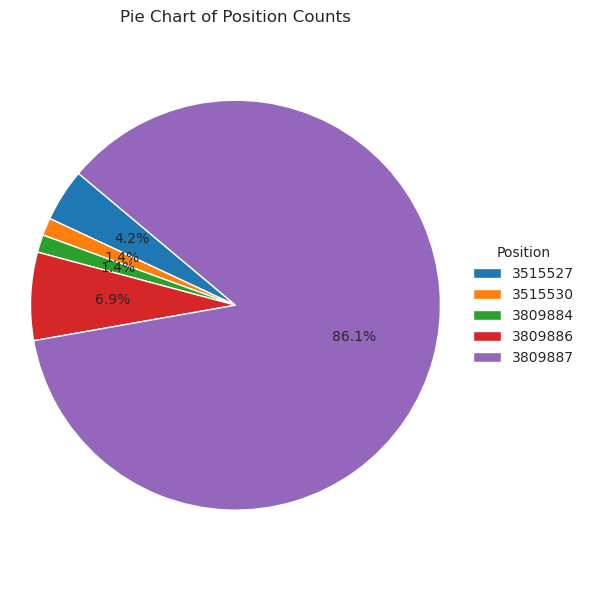

In [9]:
plt.figure(figsize=(6,6))
wedges, texts, autotexts = plt.pie(
    position_counts.values,
    autopct='%1.1f%%',
    startangle=140
)

# Add legend
plt.legend(wedges, position_counts.index.astype(str), title="Position", loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)

plt.title('Pie Chart of Position Counts')
plt.axis('equal')  # Equal aspect ratio ensures the pie is circular
plt.tight_layout()
plt.show()

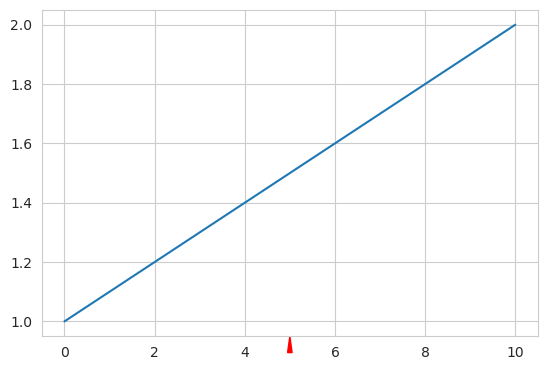

In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Sample plot
plt.plot([0, 10], [1, 2])

# Define x-position for the triangle
x_pos = 5
triangle_width = 0.1
triangle_height = 0.05  # in axis coordinates (relative to axes height)

# Get current axes
ax = plt.gca()

# Define triangle in axis coordinates (y=0 is bottom of axes)
transform = ax.get_xaxis_transform()  # Transforms x in data, y in axes coordinates

# Create triangle below the x-axis
triangle = patches.Polygon(
    [[x_pos - triangle_width / 2, -triangle_height],
     [x_pos + triangle_width / 2, -triangle_height],
     [x_pos, 0]],  # pointing up toward axis
    transform=transform,
    clip_on=False,  # Draw outside plot area
    color='red'
)

# Add triangle
ax.add_patch(triangle)

# Optional: make room below axis
plt.subplots_adjust(bottom=0.2)

plt.show()
